# Synthetic Chest X-rays with a Conditional GAN — Fighting Data Scarcity in Medical Imaging

## Problem statement
Medical-imaging AI is starved of data: images are expensive to label (expert radiologists), hard to share
(patient privacy, GDPR/HIPAA), and **imbalanced** — in the pediatric pneumonia dataset used here, NORMAL X-rays are
outnumbered ~3:1 by PNEUMONIA.

**Question:** can a **class-conditional GAN** learn to generate realistic chest X-rays of a *requested* class, and is that
synthetic data actually **useful**?

We answer it with three kinds of evidence:
1. **Realism** — visual inspection and the **Fréchet Inception Distance (FID)**, compared against a real-vs-real reference.
2. **Privacy / memorisation** — are generated images new, or copies of training patients? (nearest-neighbour analysis)
3. **Utility** — downstream pneumonia classifiers trained with and without synthetic data, all tested on the same real,
   held-out test set:
   * **TSTR** (*train on synthetic, test on real*) — could a hospital train a model on shared synthetic data only?
   * **Low-data regime** — a small clinic with 10 % of the data, with and without synthetic augmentation.
   * **Class balancing** — topping up the minority NORMAL class with synthetic images.

**Model:** a conditional DCGAN at 64 × 64 with a **projection discriminator**, **spectral normalisation**, **hinge loss**,
**DiffAugment** (to stop the discriminator overfitting a small dataset) and an **EMA generator** — standard
ingredients of modern, stable GAN training.

**Data:** Chest X-ray Images (Pneumonia), Kermany et al., *Cell* 2018 — 5,856 pediatric X-rays (CC BY 4.0).

**Run on Google Colab:** *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all* (≈ 30–40 min).

> ⚠️ Educational project — synthetic medical images must never be used clinically without rigorous validation.

## 0. Setup & pull the dataset

In [1]:
import os, io, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from PIL import Image
from scipy import linalg
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, confusion_matrix
import tensorflow as tf
import keras
from keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE
OUT_DIR = "gan_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "none (enable it: Runtime → Change runtime type)")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
DATA_DIR = "data"
XRAY_REPO = "https://huggingface.co/datasets/hf-vision/chest-xray-pneumonia/resolve/main/data/"
XRAY_FILES = {
    "train": [f"train-{i:05d}-of-00007.parquet" for i in range(7)],
    "validation": ["validation-00000-of-00001.parquet"],
    "test": ["test-00000-of-00001.parquet"],
}

def download(url, rel_path):
    path = os.path.join(DATA_DIR, rel_path)
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        print(f"downloading {rel_path} ...", flush=True)
        urllib.request.urlretrieve(url, path + ".part")
        os.replace(path + ".part", path)
    return path

for files in XRAY_FILES.values():
    for f in files:
        download(XRAY_REPO + f, f"chest_xray/{f}")
print("Dataset ready.")

downloading chest_xray/train-00000-of-00007.parquet ...
downloading chest_xray/train-00001-of-00007.parquet ...
downloading chest_xray/train-00002-of-00007.parquet ...
downloading chest_xray/train-00003-of-00007.parquet ...
downloading chest_xray/train-00004-of-00007.parquet ...
downloading chest_xray/train-00005-of-00007.parquet ...
downloading chest_xray/train-00006-of-00007.parquet ...
downloading chest_xray/validation-00000-of-00001.parquet ...
downloading chest_xray/test-00000-of-00001.parquet ...
Dataset ready.


## 1. Load the X-rays at 64 × 64

In [3]:
CLASS_NAMES = ["NORMAL", "PNEUMONIA"]
N_CLASSES = 2
IMG = 64

def load_xrays(split, size):
    cache = os.path.join(DATA_DIR, f"chest_xray_{split}_{size}.npz")
    if os.path.exists(cache):
        d = np.load(cache)
        return d["x"], d["y"]
    xs, ys = [], []
    for f in XRAY_FILES[split]:
        table = pq.read_table(download(XRAY_REPO + f, f"chest_xray/{f}"))
        for img, label in zip(table.column("image").to_pylist(), table.column("label").to_pylist()):
            im = Image.open(io.BytesIO(img["bytes"]))
            im.draft("L", (size * 2, size * 2))
            im = im.convert("L").resize((size, size), Image.LANCZOS)
            xs.append(np.asarray(im, np.uint8))
            ys.append(label)
    x, y = np.stack(xs)[..., None], np.array(ys, np.int32)
    np.savez_compressed(cache, x=x, y=y)
    return x, y

xa, ya = load_xrays("train", IMG)
xb, yb = load_xrays("validation", IMG)
x_test_u8, y_test = load_xrays("test", IMG)

# The GAN only ever sees non-test images; the test set is reserved for the utility experiments.
x_real = np.concatenate([xa, xb]).astype("float32") / 127.5 - 1.0      # [-1, 1] to match tanh
y_real = np.concatenate([ya, yb])
x_test = x_test_u8.astype("float32") / 127.5 - 1.0

for name, y in [("GAN training set", y_real), ("held-out test set", y_test)]:
    n, p = np.bincount(y)
    print(f"{name:18s} {len(y):5d} | NORMAL {n} | PNEUMONIA {p} (imbalance {p / n:.1f}:1)")

GAN training set    5232 | NORMAL 1349 | PNEUMONIA 3883 (imbalance 2.9:1)
held-out test set    624 | NORMAL 234 | PNEUMONIA 390 (imbalance 1.7:1)


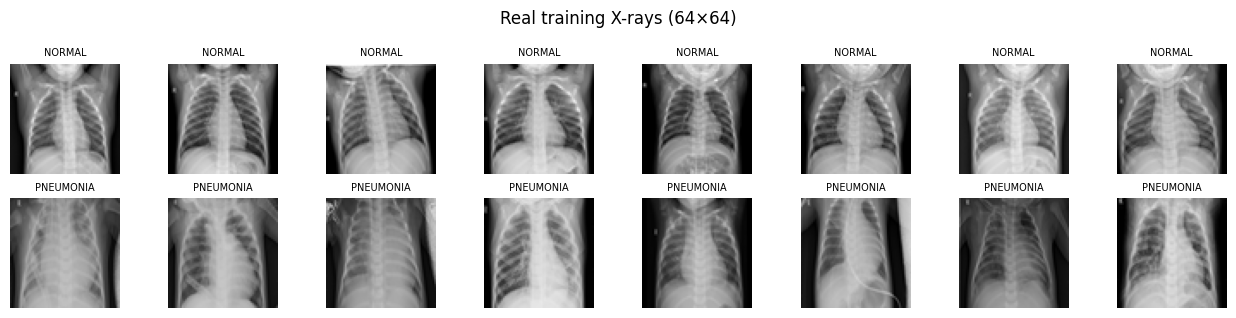

In [4]:
def show_grid(imgs, labels=None, rows=2, title=None, size=1.6, path=None):
    cols = int(np.ceil(len(imgs) / rows))
    fig = plt.figure(figsize=(cols * size, rows * size))
    for i, im in enumerate(imgs):
        ax = plt.subplot(rows, cols, i + 1)
        ax.imshow((np.squeeze(im) + 1) / 2, cmap="gray", vmin=0, vmax=1)
        if labels is not None:
            ax.set_title(CLASS_NAMES[labels[i]], fontsize=7)
        ax.axis("off")
    if title:
        plt.suptitle(title)
    plt.tight_layout()
    if path:
        fig.savefig(path, dpi=100)
    plt.show()

rng = np.random.default_rng(SEED)
idx = np.concatenate([rng.choice(np.where(y_real == c)[0], 8, replace=False) for c in range(2)])
show_grid(x_real[idx], y_real[idx], title="Real training X-rays (64×64)")

## 2. Conditional generator
`[noise z (128) ‖ class embedding]` → 4×4×512 → four transposed-conv up-sampling blocks → 64×64×1 (`tanh`).

In [5]:
LATENT = 128

def build_generator():
    z = keras.Input((LATENT,), name="z")
    label = keras.Input((1,), dtype="int32", name="label")
    e = layers.Flatten()(layers.Embedding(N_CLASSES, 32)(label))
    h = layers.Concatenate()([z, e])
    h = layers.Dense(4 * 4 * 512, use_bias=False)(h)
    h = layers.ReLU()(layers.BatchNormalization()(h))
    h = layers.Reshape((4, 4, 512))(h)
    for ch in [256, 128, 64, 32]:                                    # 8 → 16 → 32 → 64
        h = layers.Conv2DTranspose(ch, 4, strides=2, padding="same", use_bias=False)(h)
        h = layers.ReLU()(layers.BatchNormalization()(h))
    out = layers.Conv2D(1, 3, padding="same", activation="tanh")(h)
    return keras.Model([z, label], out, name="generator")

G = build_generator()
G.summary()

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ label (InputLayer)  │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 1, 32)     │         64 │ label[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (InputLayer)      │ (None, 128)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 32)        │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 160)       │          0 │ z[0][0],          │
│ (Concatenate)       │                   │            │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 8192)      │  1,310,720 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 8192)      │     32,768 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 8192)      │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 4, 4, 512) │          0 │ re_lu[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 8, 8, 256) │  2,097,152 │ reshape[0][0]     │
│ (Conv2DTranspose)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 8, 256) │      1,024 │ conv2d_transpose… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 8, 8, 256) │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_1  │ (None, 16, 16,    │    524,288 │ re_lu_1[0][0]     │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        512 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 16, 16,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_2  │ (None, 32, 32,    │    131,072 │ re_lu_2[0][0]     │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_3  │ (None, 64, 64,    │     32,768 │ re_lu_3[0][0]     │
│ (Conv2DTranspose)   │ 32)               │            │                 

 Total params: 4,131,041 (15.76 MB)

 Trainable params: 4,113,697 (15.69 MB)

 Non-trainable params: 17,344 (67.75 KB)

## 3. Projection discriminator with spectral normalisation
* **Spectral normalisation** constrains each layer's Lipschitz constant → much more stable training.
* **Projection** (Miyato & Koyama, 2018): the class enters as an inner product between a learned class embedding and the image
  features — the discriminator judges both *"is it real?"* and *"does it match the requested class?"*.

In [6]:
SN = layers.SpectralNormalization

def build_discriminator():
    img = keras.Input((IMG, IMG, 1), name="image")
    label = keras.Input((1,), dtype="int32", name="label")
    h = img
    for ch in [64, 128, 256, 512]:                                   # 32 → 16 → 8 → 4
        h = SN(layers.Conv2D(ch, 4, strides=2, padding="same"))(h)
        h = layers.LeakyReLU(0.2)(h)
    feat = layers.GlobalAveragePooling2D()(h)                        # (batch, 512)
    unconditional = SN(layers.Dense(1))(feat)
    class_emb = layers.Flatten()(layers.Embedding(N_CLASSES, 512)(label))
    projection = layers.Dot(axes=1)([feat, class_emb])
    logit = layers.Add()([unconditional, projection])
    return keras.Model([img, label], logit, name="discriminator")

D = build_discriminator()
D.summary()

Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 64, 64, 1) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spectral_normaliza… │ (None, 32, 32,    │      1,152 │ image[0][0]       │
│ (SpectralNormaliza… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 32, 32,    │          0 │ spectral_normali… │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spectral_normaliza… │ (None, 16, 16,    │    131,328 │ leaky_re_lu[0][0] │
│ (SpectralNormaliza… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 16, 16,    │          0 │ spectral_normali… │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spectral_normaliza… │ (None, 8, 8, 256) │    524,800 │ leaky_re_lu_1[0]… │
│ (SpectralNormaliza… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_2       │ (None, 8, 8, 256) │          0 │ spectral_normali… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spectral_normaliza… │ (None, 4, 4, 512) │  2,098,176 │ leaky_re_lu_2[0]… │
│ (SpectralNormaliza… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ label (InputLayer)  │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_3       │ (None, 4, 4, 512) │          0 │ spectral_normali… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 1, 512)    │      1,024 │ label[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ leaky_re_lu_3[0]… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 512)       │          0 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spectral_normaliza… │ (None, 1)         │        514 │ global_average_p… │
│ (SpectralNormaliza… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dot (Dot)           │ (None, 1)         │          0 │ global_average_p… │
│                     │                   │            │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 1)         │          0 │ spectral_normali… │
│                     │                   │            │ dot[0][0]         │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,756,994 (10.52 MB)

 Trainable params: 2,756,033 (10.51 MB)

 Non-trainable params: 961 (3.75 KB)

## 4. Training objective
* **Hinge loss** — D: `relu(1 − D(real)) + relu(1 + D(fake))`; G: `−D(fake)`.
* **DiffAugment** (Zhao et al., 2020) — the *same* random brightness/contrast/translation is applied to real **and** fake
  images before D. With only ~5.8k images, D would otherwise memorise the training set and training collapses.
* **EMA generator** — an exponential moving average of G's weights, used for all sampling; it gives smoother, higher-quality images.

In [7]:
def diff_augment(x):
    b = tf.shape(x)[0]
    x = x + (tf.random.uniform([b, 1, 1, 1]) - 0.5) * 0.4                          # brightness
    mean = tf.reduce_mean(x, axis=[1, 2, 3], keepdims=True)
    x = (x - mean) * tf.random.uniform([b, 1, 1, 1], 0.75, 1.25) + mean             # contrast
    pad = IMG // 8
    x = tf.pad(x, [[0, 0], [pad, pad], [pad, pad], [0, 0]], mode="REFLECT")          # translation
    return tf.image.random_crop(x, tf.stack([b, IMG, IMG, 1]))

G_ema = build_generator()
G_ema.set_weights(G.get_weights())
EMA_DECAY = 0.999

g_opt = keras.optimizers.Adam(2e-4, beta_1=0.5, beta_2=0.999)
d_opt = keras.optimizers.Adam(2e-4, beta_1=0.5, beta_2=0.999)

@tf.function
def train_step(real, labels):
    b = tf.shape(real)[0]
    with tf.GradientTape() as d_tape:
        fake = G([tf.random.normal([b, LATENT]), labels], training=True)
        d_real = D([diff_augment(real), labels], training=True)
        d_fake = D([diff_augment(fake), labels], training=True)
        d_loss = tf.reduce_mean(tf.nn.relu(1.0 - d_real)) + tf.reduce_mean(tf.nn.relu(1.0 + d_fake))
    d_opt.apply_gradients(zip(d_tape.gradient(d_loss, D.trainable_variables), D.trainable_variables))

    with tf.GradientTape() as g_tape:
        fake = G([tf.random.normal([b, LATENT]), labels], training=True)
        g_loss = -tf.reduce_mean(D([diff_augment(fake), labels], training=True))
    g_opt.apply_gradients(zip(g_tape.gradient(g_loss, G.trainable_variables), G.trainable_variables))

    for w, w_ema in zip(G.weights, G_ema.weights):
        w_ema.assign(EMA_DECAY * w_ema + (1.0 - EMA_DECAY) * w)
    return d_loss, g_loss, tf.reduce_mean(d_real), tf.reduce_mean(d_fake)

## 5. Train
Each grid row uses the **same noise vectors**: top row conditioned on NORMAL, bottom row on PNEUMONIA — so you can see
the label alone changing the anatomy.

epoch   25 | D loss 1.751 | G loss -0.247 | D(real) +0.46 | D(fake) +0.15 | 292s
epoch   50 | D loss 1.780 | G loss -0.196 | D(real) +0.49 | D(fake) +0.18 | 576s
epoch   75 | D loss 1.926 | G loss -0.124 | D(real) +0.25 | D(fake) +0.17 | 871s
epoch  100 | D loss 1.902 | G loss -0.540 | D(real) +0.57 | D(fake) +0.43 | 1155s


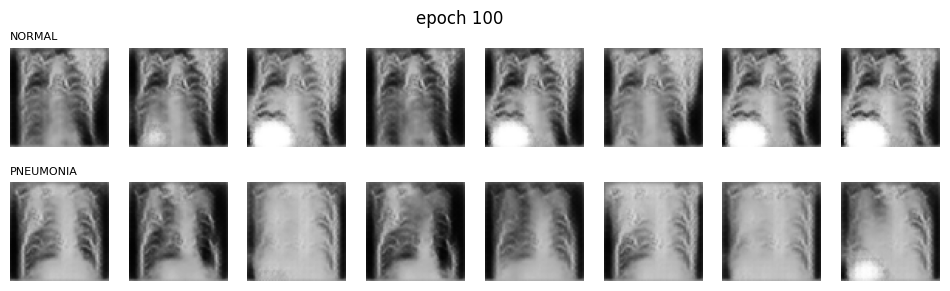

epoch  125 | D loss 1.921 | G loss -0.536 | D(real) +0.54 | D(fake) +0.43 | 1449s
epoch  150 | D loss 1.895 | G loss -0.069 | D(real) +0.19 | D(fake) +0.07 | 1735s
epoch  175 | D loss 1.922 | G loss -0.285 | D(real) +0.36 | D(fake) +0.28 | 2021s
epoch  200 | D loss 1.947 | G loss -0.077 | D(real) +0.17 | D(fake) +0.11 | 2306s


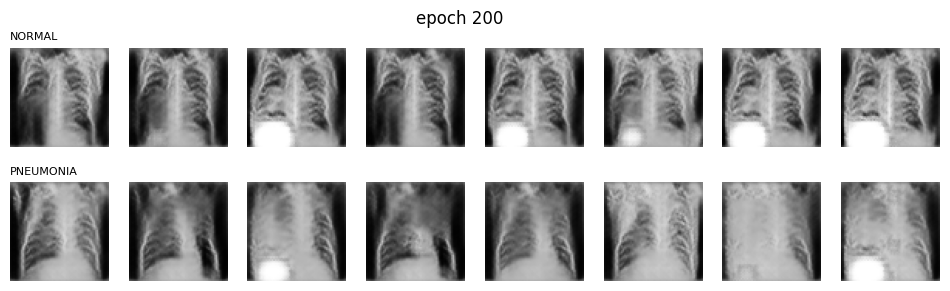

epoch  225 | D loss 1.964 | G loss -0.302 | D(real) +0.38 | D(fake) +0.33 | 2593s
epoch  250 | D loss 1.924 | G loss 0.054 | D(real) +0.09 | D(fake) +0.00 | 2878s
epoch  275 | D loss 1.932 | G loss -0.084 | D(real) +0.17 | D(fake) +0.09 | 3165s
epoch  300 | D loss 1.903 | G loss 0.151 | D(real) +0.03 | D(fake) -0.07 | 3451s


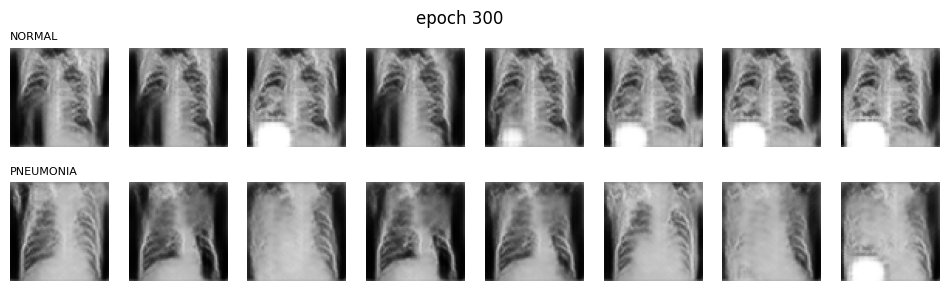

In [8]:
EPOCHS = 300
SAMPLE_EVERY = 25
BATCH = 64

gan_ds = (tf.data.Dataset.from_tensor_slices((x_real, y_real[:, None]))
          .shuffle(len(x_real), seed=SEED).batch(BATCH, drop_remainder=True).prefetch(AUTOTUNE))

fixed_z = tf.random.normal([8, LATENT], seed=SEED)
fixed_z = tf.concat([fixed_z, fixed_z], 0)
fixed_y = tf.constant([[0]] * 8 + [[1]] * 8)

def snapshot(epoch, show):
    imgs = G_ema([fixed_z, fixed_y], training=False).numpy()
    fig = plt.figure(figsize=(12, 3.2))
    for i in range(16):
        ax = plt.subplot(2, 8, i + 1)
        ax.imshow((imgs[i, :, :, 0] + 1) / 2, cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
        if i % 8 == 0:
            ax.set_title(CLASS_NAMES[i // 8], fontsize=8, loc="left")
    plt.suptitle(f"epoch {epoch}")
    fig.savefig(os.path.join(OUT_DIR, f"epoch_{epoch:04d}.png"), dpi=80)
    plt.show() if show else plt.close(fig)

history = []
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    stats = np.mean([[float(v) for v in train_step(xb, yb)] for xb, yb in gan_ds], axis=0)
    history.append(stats)
    if epoch % SAMPLE_EVERY == 0 or epoch == EPOCHS:
        print(f"epoch {epoch:4d} | D loss {stats[0]:.3f} | G loss {stats[1]:.3f} | "
              f"D(real) {stats[2]:+.2f} | D(fake) {stats[3]:+.2f} | {time.time() - t0:.0f}s")
        snapshot(epoch, show=(epoch % (SAMPLE_EVERY * 4) == 0 or epoch == EPOCHS))
history = np.array(history)

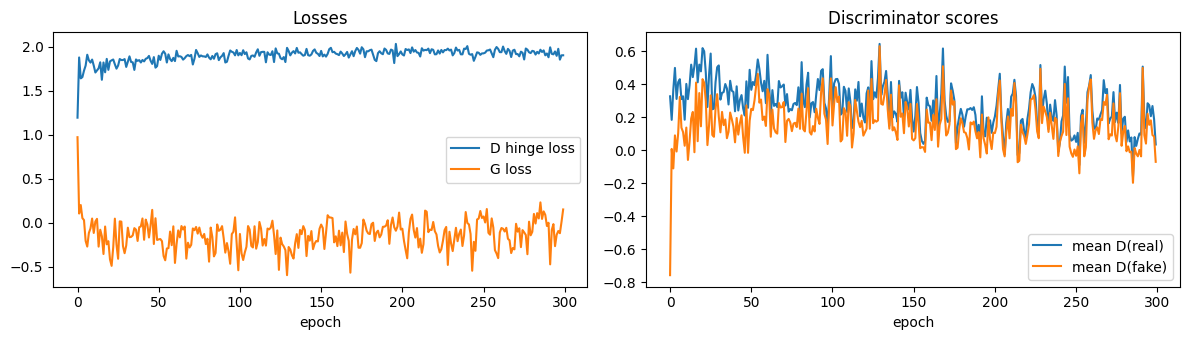

Saved gan_outputs/training.gif


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(history[:, 0], label="D hinge loss"); ax[0].plot(history[:, 1], label="G loss")
ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].set_title("Losses")
ax[1].plot(history[:, 2], label="mean D(real)"); ax[1].plot(history[:, 3], label="mean D(fake)")
ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].set_title("Discriminator scores")
plt.tight_layout(); plt.show()

frames = [Image.open(os.path.join(OUT_DIR, f)) for f in sorted(os.listdir(OUT_DIR)) if f.startswith("epoch_")]
frames[0].save(os.path.join(OUT_DIR, "training.gif"), save_all=True, append_images=frames[1:], duration=400, loop=0)
print("Saved", os.path.join(OUT_DIR, "training.gif"))

## 6. Generated samples vs. real images

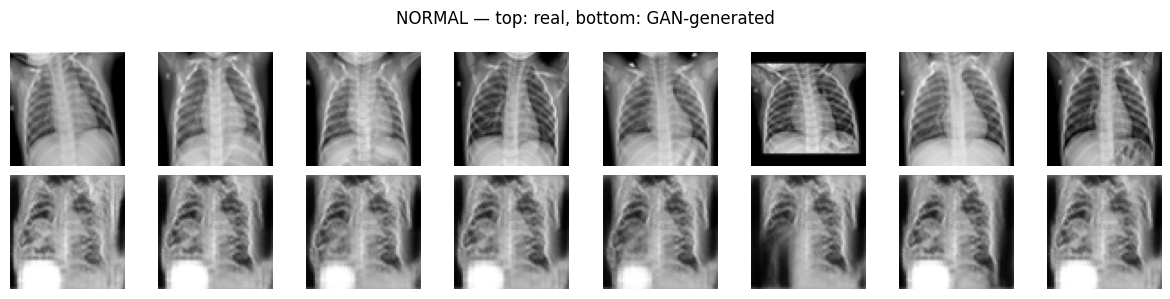

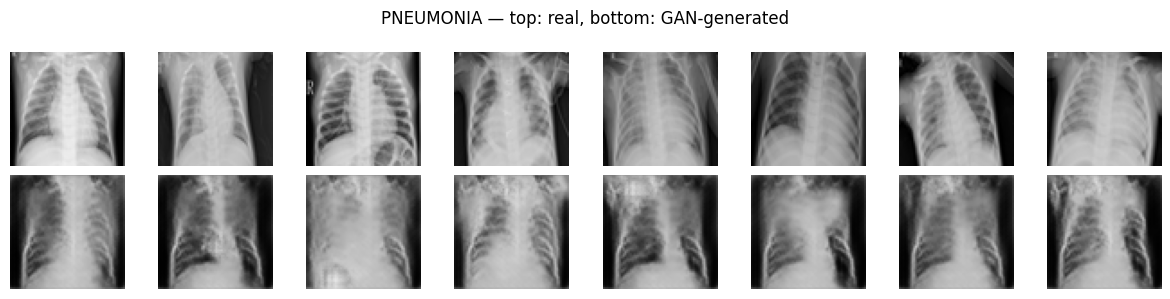

In [10]:
def generate(n, cls, batch=500):
    out = []
    for i in range(0, n, batch):
        m = min(batch, n - i)
        out.append(G_ema([tf.random.normal([m, LATENT]), tf.fill([m, 1], cls)], training=False).numpy())
    return np.concatenate(out)

for c in range(2):
    real = x_real[rng.choice(np.where(y_real == c)[0], 8, replace=False)]
    fake = generate(8, c)
    show_grid(np.concatenate([real, fake]), rows=2, size=1.5,
              title=f"{CLASS_NAMES[c]} — top: real, bottom: GAN-generated",
              path=os.path.join(OUT_DIR, f"real_vs_fake_{CLASS_NAMES[c]}.png"))

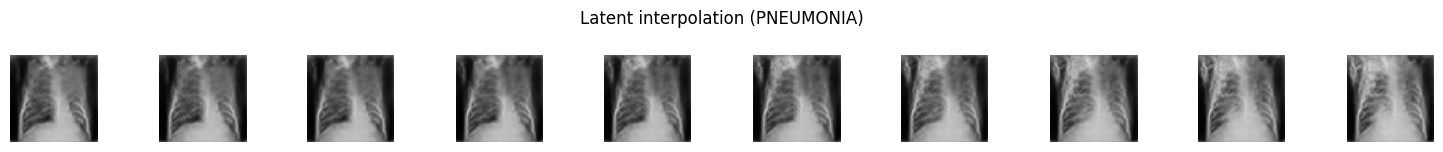

In [11]:
# Latent-space interpolation (within PNEUMONIA) — smooth transitions mean G learned a continuous anatomy manifold
z1, z2 = tf.random.normal([2, LATENT], seed=3)
alphas = np.linspace(0, 1, 10)
zs = tf.stack([(1 - a) * z1 + a * z2 for a in alphas])
show_grid(G_ema([zs, tf.ones([10, 1], tf.int32)], training=False).numpy(), rows=1, size=1.5,
          title="Latent interpolation (PNEUMONIA)")

## 7. Realism — Fréchet Inception Distance (FID)
FID compares the statistics of InceptionV3 features of two image sets (lower = more similar).
Because FID depends on sample size and ImageNet features are not tuned for X-rays, we read it **relative to a reference**:
the FID between the real *test* set and the real *training* set — about as low as a perfect generator could go.

In [12]:
inception = keras.applications.InceptionV3(include_top=False, pooling="avg", input_shape=(299, 299, 3))

def inception_features(x, batch=100):              # x in [-1, 1], exactly InceptionV3's expected range
    feats = []
    for i in range(0, len(x), batch):
        b = tf.image.resize(x[i:i + batch], (299, 299))
        feats.append(inception(tf.repeat(b, 3, axis=-1), training=False).numpy())
    return np.concatenate(feats).astype(np.float64)

def fid(f1, f2):
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    covmean = linalg.sqrtm(s1 @ s2)
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * covmean.real))

N_FID = len(x_test)
N_REF = min(2000, len(x_real))
ref_idx = rng.choice(len(x_real), N_REF, replace=False)
f_ref = inception_features(x_real[ref_idx])
f_test = inception_features(x_test[:N_FID])
n_norm = int(np.round(N_FID * np.mean(y_real[ref_idx] == 0)))
f_fake = inception_features(np.concatenate([generate(n_norm, 0), generate(N_FID - n_norm, 1)]))
noise = np.clip(rng.normal(0, 0.5, size=(N_FID, IMG, IMG, 1)), -1, 1).astype("float32")
f_noise = inception_features(noise)

fid_table = pd.Series({
    "real test  vs real train (reference floor)": fid(f_test, f_ref),
    "GAN samples vs real train": fid(f_fake, f_ref),
    "random noise vs real train (sanity ceiling)": fid(f_noise, f_ref),
}, name=f"FID (n={N_FID} vs {N_REF})").round(1)
display(fid_table.to_frame())

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


/tmp/ipykernel_541/2164686120.py:13: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = linalg.sqrtm(s1 @ s2)


,FID (n=624 vs 2000)
real test vs real train (reference floor),21.0
GAN samples vs real train,193.4
random noise vs real train (sanity ceiling),632.2


## 8. Privacy check — is the GAN copying training patients?
For generated images we find the **nearest training image** (pixel L2 distance) and compare against the same distance for
*real test images* (which are genuinely new patients). If generated images were much closer to the training set than
new real patients are, the GAN would be memorising — a privacy leak.

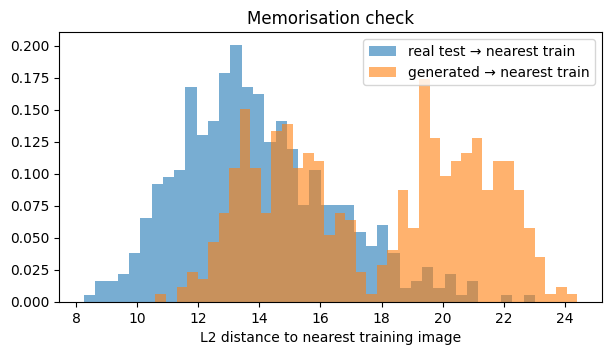

median distance — new real patients: 13.7 | generated: 18.2
generated images closer than the closest real test image: 0 / 500


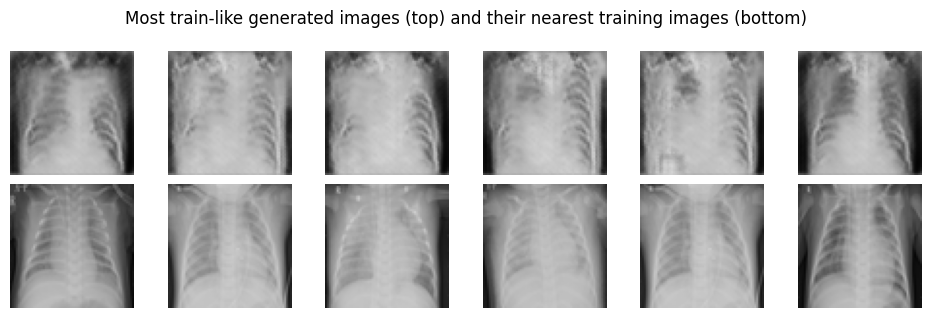

In [13]:
train_flat = x_real.reshape(len(x_real), -1)
train_sq = (train_flat ** 2).sum(1)

def nn_dist(x):
    q = x.reshape(len(x), -1)
    d2 = (q ** 2).sum(1)[:, None] + train_sq[None] - 2 * q @ train_flat.T
    return np.sqrt(np.maximum(d2, 0)).min(1), np.sqrt(np.maximum(d2, 0)).argmin(1)

fake_nn = np.concatenate([generate(250, 0), generate(250, 1)])
d_fake, nn_idx = nn_dist(fake_nn)
d_test, _ = nn_dist(x_test[:500])

plt.figure(figsize=(7, 3.5))
plt.hist(d_test, bins=40, alpha=0.6, density=True, label="real test → nearest train")
plt.hist(d_fake, bins=40, alpha=0.6, density=True, label="generated → nearest train")
plt.xlabel("L2 distance to nearest training image"); plt.legend(); plt.title("Memorisation check")
plt.show()
print(f"median distance — new real patients: {np.median(d_test):.1f} | generated: {np.median(d_fake):.1f}")
print(f"generated images closer than the closest real test image: {(d_fake < d_test.min()).sum()} / {len(d_fake)}")

pick = np.argsort(d_fake)[:6]                       # the 6 MOST suspicious (closest) generated images
show_grid(np.concatenate([fake_nn[pick], x_real[nn_idx[pick]]]), rows=2, size=1.6,
          title="Most train-like generated images (top) and their nearest training images (bottom)")

## 9. Utility — does synthetic data help a pneumonia classifier?
Same small CNN, same training recipe, same **real held-out test set** for every experiment. We report ROC-AUC
(threshold-free) plus sensitivity / specificity at 0.5 (with balanced class weights).

The low-data scenario models **privacy-preserving data sharing**: a large hospital trains the GAN on its data and shares
only *synthetic* images with a small clinic that has 10 % as much real data.

In [14]:
CLF_EPOCHS = 30

def build_classifier():
    return keras.Sequential([
        layers.Input((IMG, IMG, 1)),
        layers.RandomRotation(0.03), layers.RandomTranslation(0.05, 0.05), layers.RandomZoom(0.1),
        *[blk for ch in [32, 64, 128] for blk in (
            layers.Conv2D(ch, 3, padding="same", use_bias=False), layers.BatchNormalization(), layers.ReLU(),
            layers.MaxPooling2D())],
        layers.Conv2D(256, 3, padding="same", activation="relu"),
        layers.GlobalAveragePooling2D(), layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ])

def run_experiment(name, x, y):
    keras.utils.set_random_seed(SEED)
    x_tr, x_va, y_tr, y_va = train_test_split(x, y, test_size=0.15, stratify=y, random_state=SEED)
    cw = {c: len(y_tr) / (2 * n) for c, n in enumerate(np.bincount(y_tr))}
    clf = build_classifier()
    clf.compile(keras.optimizers.Adam(1e-3), "binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
    clf.fit(x_tr, y_tr, validation_data=(x_va, y_va), epochs=CLF_EPOCHS, batch_size=64, class_weight=cw, verbose=0,
            callbacks=[keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6, restore_best_weights=True)])
    p = clf.predict(x_test, verbose=0).ravel()
    tn, fp, fn, tp = confusion_matrix(y_test, (p >= 0.5).astype(int)).ravel()
    res = {"train images": len(x), "real": int(name_real[name]), "synthetic": len(x) - int(name_real[name]),
           "test AUC": roc_auc_score(y_test, p), "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp)}
    print(f"{name:42s} AUC {res['test AUC']:.3f} | sens {res['sensitivity']:.3f} | spec {res['specificity']:.3f}")
    return res

# Real subsets
_, x_small, _, y_small = train_test_split(x_real, y_real, test_size=0.10, stratify=y_real, random_state=SEED)
N_SYN = 2000                                                       # synthetic images per class
x_syn = np.concatenate([generate(N_SYN, 0), generate(N_SYN, 1)])
y_syn = np.repeat([0, 1], N_SYN).astype(np.int32)
n_gap = int((y_real == 1).sum() - (y_real == 0).sum())             # NORMALs needed to balance the classes
x_bal_syn = generate(n_gap, 0)

experiments = {
    "A. Real — all":                          (x_real, y_real, len(x_real)),
    "B. Synthetic only (TSTR)":               (x_syn, y_syn, 0),
    "C. Real — 10% (small clinic)":           (x_small, y_small, len(x_small)),
    "D. Real 10% + synthetic":                (np.concatenate([x_small, x_syn]), np.concatenate([y_small, y_syn]), len(x_small)),
    "E. Real — all + synthetic NORMAL (balanced)": (np.concatenate([x_real, x_bal_syn]),
                                                 np.concatenate([y_real, np.zeros(n_gap, np.int32)]), len(x_real)),
}
name_real = {k: v[2] for k, v in experiments.items()}
results = pd.DataFrame({k: run_experiment(k, x, y) for k, (x, y, _) in experiments.items()}).T
display(results.astype({"train images": int, "real": int, "synthetic": int}).round(3))

A. Real — all                              AUC 0.936 | sens 0.969 | spec 0.637
B. Synthetic only (TSTR)                   AUC 0.438 | sens 1.000 | spec 0.000
C. Real — 10% (small clinic)               AUC 0.844 | sens 0.595 | spec 0.889
D. Real 10% + synthetic                    AUC 0.926 | sens 0.972 | spec 0.624
E. Real — all + synthetic NORMAL (balanced) AUC 0.924 | sens 0.985 | spec 0.453


,train images,real,synthetic,test AUC,sensitivity,specificity
A. Real — all,5232,5232,0,0.936,0.969,0.637
B. Synthetic only (TSTR),4000,0,4000,0.438,1.000,0.000
C. Real — 10% (small clinic),524,524,0,0.844,0.595,0.889
D. Real 10% + synthetic,4524,524,4000,0.926,0.972,0.624
E. Real — all + synthetic NORMAL (balanced),7766,5232,2534,0.924,0.985,0.453


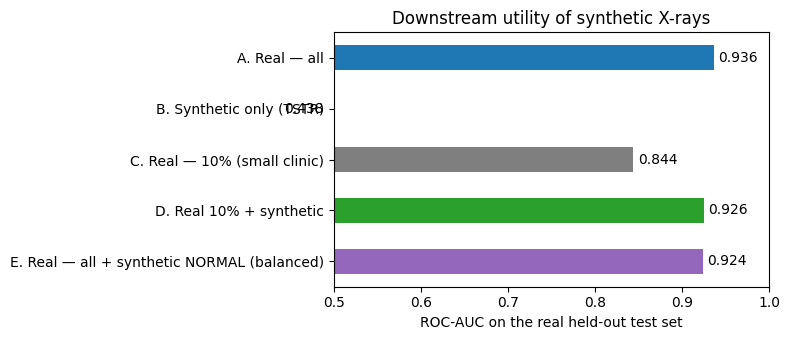

In [15]:
ax = results["test AUC"].astype(float).plot.barh(figsize=(8, 3.5), xlim=(0.5, 1.0), color=
    ["tab:blue", "tab:orange", "tab:gray", "tab:green", "tab:purple"])
for i, v in enumerate(results["test AUC"].astype(float)):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center")
ax.invert_yaxis(); ax.set_xlabel("ROC-AUC on the real held-out test set"); ax.set_title("Downstream utility of synthetic X-rays")
plt.tight_layout(); plt.show()

**How to read this table**
* **B vs A** — how much diagnostic signal the synthetic images carry on their own. TSTR well above 0.5 means the GAN
  learned *class-specific* anatomy, not just "something that looks like an X-ray".
* **D vs C** — whether shared synthetic data helps a data-poor site. This is the scenario where generative augmentation
  is most likely to pay off.
* **E vs A** — whether synthetic minority-class images help with imbalance. With ~5.8k real images and class weights
  already in place, gains here are often small — an honest, common finding.

Results are from a single seed; differences of ~0.01 AUC are within run-to-run noise. Re-run with a few seeds for firm conclusions.

In [16]:
os.makedirs("models", exist_ok=True)
G_ema.save("models/xray_cgan_generator_ema.keras")
D.save("models/xray_cgan_discriminator.keras")
results.to_csv(os.path.join(OUT_DIR, "utility_results.csv"))
fid_table.to_csv(os.path.join(OUT_DIR, "fid.csv"))
print("Saved generator, discriminator and result tables")
# Generate later:  G = keras.models.load_model("models/xray_cgan_generator_ema.keras")
#                  G([tf.random.normal([16, 128]), tf.fill([16, 1], 0)])   # 16 NORMAL X-rays

Saved generator, discriminator and result tables


---
## Summary & limitations
* Built a **class-conditional GAN** (projection discriminator + spectral norm + hinge loss + DiffAugment + EMA) that
  generates NORMAL or PNEUMONIA chest X-rays on demand.
* Evaluated it on **realism** (FID vs a real-data reference), **privacy** (nearest-neighbour memorisation check) and
  **utility** (TSTR, low-data augmentation, class balancing) against a real held-out test set.

**Limitations:** 64 × 64 resolution loses fine detail radiologists use; single-hospital pediatric data; FID uses ImageNet
features; the nearest-neighbour test is a heuristic, not a formal privacy guarantee (that would need e.g. differentially-private training).
**Next steps:** a 128/256 px model (StyleGAN2-ADA or a diffusion model), radiologist Turing tests, multi-seed experiments.

### Download results (Colab)
Colab files are deleted when the session ends.

In [17]:
import shutil
os.makedirs("gan_results", exist_ok=True)
shutil.copytree(OUT_DIR, "gan_results/gan_outputs", dirs_exist_ok=True)
shutil.copytree("models", "gan_results/models", dirs_exist_ok=True)
shutil.make_archive("gan_results", "zip", "gan_results")
try:
    from google.colab import files
    files.download("gan_results.zip")
except ImportError:
    print("Not on Colab — results saved to gan_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>